# Project Visualizations

In [1]:
#Import necessary packages
import numpy as np
import pandas as pd
import seaborn as sns

## Load NYPD Arrests Data

In [2]:
nypd_2021 = pd.read_csv("NYPD_Arrest_Data__Year_to_Date_.csv")
nypd_2006_2020 = pd.read_csv("NYPD_Arrests_Data__Historic_.csv")
#nypd_2021.to_sql(table_name, conn, if_exists='append', index=False)

nypd_arrests = pd.concat([nypd_2006_2020, nypd_2021], ignore_index=True)
nypd_arrests.head()

,ARREST_KEY,ARREST_DATE,PD_CD,PD_DESC,KY_CD,OFNS_DESC,LAW_CODE,LAW_CAT_CD,ARREST_BORO,ARREST_PRECINCT,JURISDICTION_CODE,AGE_GROUP,PERP_SEX,PERP_RACE,X_COORD_CD,Y_COORD_CD,Latitude,Longitude,Lon_Lat,New Georeferenced Column
0,32311380,06/18/2007,511.0,"CONTROLLED SUBSTANCE, POSSESSION 7",235.0,DANGEROUS DRUGS,PL 2200300,M,Q,27,1.0,18-24,M,BLACK,NaN,NaN,NaN,NaN,NaN,NaN
1,192799737,01/26/2019,177.0,SEXUAL ABUSE,116.0,SEX CRIMES,PL 1306503,F,M,25,0.0,45-64,M,BLACK,1000555.0,230994.0,40.800694,-73.941109,POINT (-73.94110928599997 40.800694331000045),NaN
2,193260691,02/06/2019,NaN,NaN,NaN,NaN,PL 2203400,F,M,14,0.0,25-44,M,UNKNOWN,986685.0,215375.0,40.757839,-73.991212,POINT (-73.99121211099998 40.75783900300007),NaN
3,149117452,01/06/2016,153.0,RAPE 3,104.0,RAPE,PL 1302503,F,K,67,0.0,25-44,M,BLACK,998032.0,175598.0,40.648650,-73.950336,POINT (-73.95033556299995 40.648650085000035),NaN
4,190049060,11/15/2018,157.0,RAPE 1,104.0,RAPE,PL 1303501,F,K,77,0.0,25-44,M,BLACK,1003606.0,185050.0,40.674583,-73.930222,POINT (-73.93022154099998 40.67458330800008),NaN


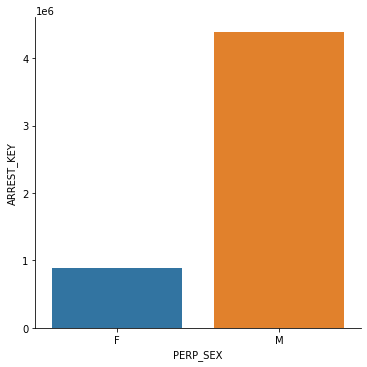

In [3]:
arrests_gender = nypd_arrests.groupby("PERP_SEX").count()
arrests_gender.head()
sns.catplot(x=arrests_gender.index, y="ARREST_KEY", kind="bar", data=arrests_gender)

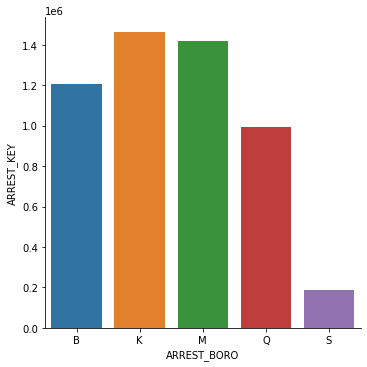

In [4]:
arrests_borough = nypd_arrests.groupby("ARREST_BORO").count()
arrests_borough.head()
sns.catplot(x=arrests_borough.index, y="ARREST_KEY", kind="bar", data=arrests_borough)

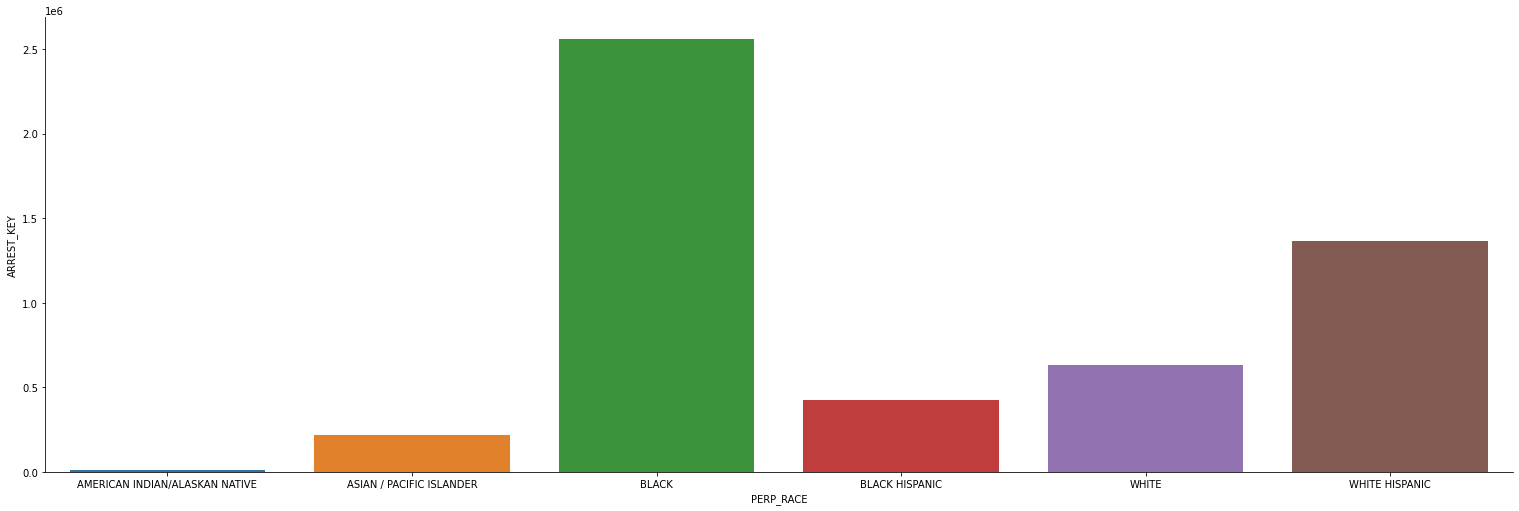

In [5]:
nypd_arrests = nypd_arrests[(nypd_arrests["PERP_RACE"] != "OTHER") & (nypd_arrests["PERP_RACE"] != "UNKNOWN")]
arrests_race = nypd_arrests.groupby("PERP_RACE").count()
arrests_race.head()
sns.catplot(x=arrests_race.index, y="ARREST_KEY", kind="bar", height=7, aspect=3, data=arrests_race)

,ARREST_KEY,ARREST_DATE,PD_CD,PD_DESC,KY_CD,OFNS_DESC,LAW_CODE,LAW_CAT_CD,ARREST_BORO,ARREST_PRECINCT,JURISDICTION_CODE,AGE_GROUP,PERP_SEX,PERP_RACE,X_COORD_CD,Y_COORD_CD,Latitude,Longitude,Lon_Lat,New Georeferenced Column
YEAR,,,,,,,,,,,,,,,,,,,,
2006,367178,367178,367116,367104,367104,367104,367116,366060,367178,367178,367170,367161,367178,367178,367178,367178,367178,367178,367178,0
2007,399179,399179,399142,399128,399128,399128,399142,398096,399179,399179,399177,399179,399179,399179,399178,399178,399178,399178,399178,0
2008,397913,397913,397891,397759,397759,397759,397891,396800,397909,397913,397913,397913,397913,397913,397913,397913,397913,397913,397913,0
2009,417464,417464,417455,417208,417208,417208,417455,416221,417461,417464,417464,417464,417464,417464,417464,417464,417464,417464,417464,0
2010,417916,417916,417909,417276,417276,417276,417909,416790,417916,417916,417916,417916,417916,417916,417916,417916,417916,417916,417916,0


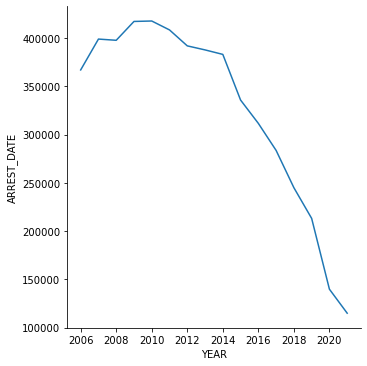

In [6]:
#print(nypd_arrests.dtypes)
nypd_arrests["ARREST_DATE"] = pd.to_datetime(nypd_arrests["ARREST_DATE"])
nypd_arrests['YEAR'] = pd.DatetimeIndex(nypd_arrests["ARREST_DATE"]).year
arrests_year = nypd_arrests.groupby('YEAR').count()
sns.relplot(data=arrests_year, x=arrests_year.index, y="ARREST_DATE", kind="line")
arrests_year.head()

There appears to be a negative relationship between year and number of arrests made such that there are fewer arrests made over the years

# Table

In [7]:
precinct_table = nypd_arrests.groupby('ARREST_PRECINCT').count()['ARREST_DATE']
precinc_table

NameError: name 'precinc_table' is not defined

# Hypothesis Testing

In [ ]:
from scipy import stats

prop_men = len(nypd_arrests[nypd_arrests["PERP_SEX"] == 'M']) / len(nypd_arrests["PERP_SEX"])
print("Proportion of men:", prop_men)

p = prop_men
n = len(nypd_arrests["PERP_SEX"])
c = len(nypd_arrests[nypd_arrests["PERP_SEX"] == 'M'])
standard_error = np.sqrt((p*(1-p))/n)
prob = ((c/n)-p)/standard_error
pr = 1-stats.t.cdf(prob, n-1)
print("P-value:", pr)

In [ ]:
boro_k = nypd_arrests[nypd_arrests["ARREST_BORO"] == 'B']
p = prop_men
n = len(boro_k["PERP_SEX"])
c = len(boro_k[boro_k["PERP_SEX"] == 'M'])
standard_error = np.sqrt((p*(1-p))/n)
prob = ((c/n)-p)/standard_error
pr = 1-stats.t.cdf(prob, n-1)
pr

From the above calculation, we can see that the proportion of arrests where the perpetrator was male was about 83%. We can hypothesize that the true percentage of male arrests is relatively similar:

**Null hypothesis (H0):** The true percentage of male arrests is 83%. 

**Alternative hypothesis (H1):** The true percentage of male arrests is not 83% (i.e. it is either higher or lower since this is a two-sided t-test).

Conducting a two-sided t-test, we get a p-value of 0.5.

Interpretation: Since the p-value = 0.5 is greater than 0.05 (our significance level), the probability that the percentage of male arrests in borough K is 83% is greater than 0.05, so we **cannot** reject the null hypothesis or draw any conclusions about the underlying population.

# Linear Regression Model

In [ ]:
# Create linear regression to model number of arrests as a function of year
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

data = arrests_year.index.values.reshape(-1, 1)
target = arrests_year["ARREST_DATE"].values
linear_model = LinearRegression()
linear_model.fit(X=data, y=target)

arrests_year["PREDICTED_ARRESTS"] = linear_model.predict(data)

mse = mean_squared_error(arrests_year["ARREST_DATE"].values, arrests_year["PREDICTED_ARRESTS"].values) # float: MSE
r2 = r2_score(arrests_year["ARREST_DATE"].values, arrests_year["PREDICTED_ARRESTS"].values) # float: R^2 score
print("MSE:", mse, "r^2:", r2)


In [ ]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely import wkt
import contextily as cx
import mapclassify
#Map of Number of Crimes by Borough in 2021
ny_boro = gpd.read_file(gpd.datasets.get_path('nybb'))
ny_boro['ARREST_BORO'] = np.where(ny_boro["BoroName"] == "Brooklyn", "K", ny_boro["BoroName"].str.slice(stop=1))
nypd_arrests_2021 = nypd_arrests[nypd_arrests["YEAR"] == 2021]
arrest_groups = nypd_arrests_2021.groupby(['ARREST_BORO']).count()
boro_arrests = ny_boro.merge(arrest_groups, on='ARREST_BORO')
boro_arrests = boro_arrests[["BoroCode", "BoroName", "Shape_Leng", "Shape_Area", "geometry", "ARREST_BORO", "ARREST_KEY"]]
print(boro_arrests)
boro_arrests['longitude']=[-8260264,-8229461,-8236843,-8238858,-8229155]
boro_arrests['latitude']=[4948597,4972778,4960893,4978915,4994269]
ny_boro_wm = boro_arrests.to_crs(epsg=3857)

ny_map = ny_boro_wm.plot(column='ARREST_KEY',figsize=(10, 10),alpha=0.8, edgecolor='k',cmap='Reds',legend=True,scheme="quantiles")
cx.add_basemap(ny_map)
# add boroughs' names with number of arrests
for i in range(len(ny_boro_wm)):
    plt.text(ny_boro_wm.longitude[i],ny_boro_wm.latitude[i],"{}\n# of Arrests: {}".format(ny_boro_wm.BoroName[i],ny_boro_wm.ARREST_KEY[i]), size = 12)    
plt.title('NYPD Arrests in 2021 by Boroughs',fontsize=25)
leg = ny_map.get_legend()
leg.set_bbox_to_anchor((1.3,1))
plt.show()

# Prediction

#### We are interested in modeling LAW_CAT_CD (level of offense: felony, misdemeanor, violation) as a function of sex, race, and age group

In [ ]:
from sklearn.model_selection import train_test_split

nypd_arrests = nypd_arrests.dropna(subset=['LAW_CAT_CD', 'AGE_GROUP', 'PERP_SEX', 'PERP_RACE'])
#nypd_arrests = nypd_arrests.drop(['New Georeferenced Column'], axis=1)

In [ ]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import plot_confusion_matrix
import matplotlib.pyplot as plt # just to format confusion matrix

sex_order = np.sort(nypd_arrests["PERP_SEX"].unique())
race_order = np.sort(nypd_arrests["PERP_RACE"].unique())

#encode arrest variable
sex_enc = OneHotEncoder(handle_unknown='ignore').fit_transform(nypd_arrests["PERP_SEX"].values.reshape(-1, 1)).toarray()
race_enc = OneHotEncoder(handle_unknown='ignore').fit_transform(nypd_arrests["PERP_RACE"].values.reshape(-1, 1)).toarray()
nypd_arrests[sex_order] = pd.DataFrame(sex_enc, index = nypd_arrests.index)
nypd_arrests[race_order] = pd.DataFrame(race_enc, index = nypd_arrests.index)
#arrests_p = nypd_arrests[["LAW_CAT_CD", "M", "F", "BLACK", "WHITE HISPANIC", "BLACK HISPANIC", "WHITE", "ASIAN / PACIFIC ISLANDER", "AMERICAN INDIAN/ALASKAN NATIVE"]]
#reviews_p[attend_order] = pd.DataFrame(attend_enc, index = reviews_p.index)

# Fit logistic regression model on train_data + train_target
p_data = nypd_arrests[["M", "F", "BLACK", "WHITE HISPANIC", "BLACK HISPANIC", "WHITE", "ASIAN / PACIFIC ISLANDER", "AMERICAN INDIAN/ALASKAN NATIVE"]]
p_target = nypd_arrests['LAW_CAT_CD']
train_data, test_data, train_target, test_target = train_test_split(     
    p_data, p_target, test_size=0.7, random_state=216)

data = train_data.values
target = train_target.values
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X=data, y=target)

# Make predictions for test_data
test_data_p = test_data.values
test_target_p = test_target.values
test_data["PREDICTED_LAW_CAT_CD"] = logistic_model.predict(test_data_p)
predicted = test_data["PREDICTED_LAW_CAT_CD"].values

score = logistic_model.score(test_data_p, test_target_p)
# Leave this line here to print the result
print("accuracy:", score)
plot_confusion_matrix(logistic_model, test_data_p, test_target_p)
plt.grid(False)

In [ ]:
arrests_grouped = nypd_arrests.groupby(['LAW_CAT_CD', 'PERP_SEX', 'PERP_RACE']).count()
arrests_grouped = arrests_grouped[['ARREST_KEY']]
arrests_grouped['PERCENT'] = (arrests_grouped['ARREST_KEY'] / 
                  arrests_grouped['ARREST_KEY'].sum()) * 100
print(arrests_grouped)